# 5.3 · 风险模型：协方差 · Barra · 因子风险 · 特质风险

> 组合优化的核心输入是**协方差矩阵**。直接用样本协方差有维度灾难、不稳定的问题。
> 工业界（公募、私募、指数增强）普遍使用**因子风险模型（Barra 式）**来稳定地估计风险。
> 本节掌握风险的分解、因子风险模型的结构，以及如何用它做风险归因。

## 一、风险的分解

股票收益可以分解为：
$$r_i = \alpha_i + \sum_k \beta_{ik} f_k + \varepsilon_i$$
- $f_k$：因子收益（市场、规模、价值…）；
- $\beta_{ik}$：股票 $i$ 在因子 $k$ 上的**暴露（exposure）**；
- $\varepsilon_i$：**特质收益（idiosyncratic）**，无法被因子解释。

对应地，风险（方差）分为：
- **系统性/因子风险**：由因子暴露带来，整个市场共同承担；
- **特质风险**：个股特有，可通过分散化消除。

## 二、样本协方差的问题

直接用历史收益算样本协方差 $\Sigma$：
- 若有 N 只股票，要估计 N(N+1)/2 个参数，N=300 时约 4.5 万个，而每只股票历史样本有限；
- 估计噪声大、可能非正定；
- 优化器会放大这些噪声。

**因子风险模型**大幅减少待估参数：
$$\Sigma = B \Sigma_f B^\top + D$$
- $B$：因子暴露（N×K，K 个因子，K 远小于 N）；
- $\Sigma_f$：因子协方差（K×K）；
- $D$：特质风险（对角矩阵）。
只需估计 K×K 的因子协方差和 N 个特质风险，**稳定、可解释**。

## 三、Barra 风格因子

Barra 多因子模型常用的风格因子（暴露直接从特征计算，截面标准化）：
- Size（规模）、Beta、Momentum（动量）、Residual Volatility（残差波动）
- Liquidity（流动性）、Value（价值）、Growth（成长）、Leverage（杠杆）、Non-linear Size

> 注意：**Barra 因子主要用于"风险"，用于解释和控制风险，而不是直接产生 alpha**。Alpha 因子在风险模型之外，组合优化时在控制 Barra 风险的前提下最大化 alpha。

## 四、构建因子风险模型（代码在 portfolio_lab.risk）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from portfolio_lab.risk import factor_risk_model, reconstruct_cov
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
ret = close.pct_change().dropna(how='all')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
exp_names = ['SMB 小市值', 'EP 盈利收益率', 'BP 账面市值比',
             'REV5 短期反转', '低波60']
exposures = {k: facs[k].rank(axis=1, pct=True)*2-1 for k in exp_names}
model = factor_risk_model(ret, exposures)
print('因子年化波动率:', np.round(np.sqrt(np.diag(model['Sigma_f'])), 3))
print('特质风险中位数: %.3f' % model['specific_risk'].median())
Sigma_rec, B = reconstruct_cov(model, exposures, ret.index[-1])
print('重建协方差:', Sigma_rec.shape, '正定:', np.all(np.linalg.eigvalsh(Sigma_rec) > 0))

[6344:MainThread](2026-10-30 01:37:45,400) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[6344:MainThread](2026-10-30 01:37:46,859) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[6344:MainThread](2026-10-30 01:37:46,860) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


因子年化波动率: [0.069 0.083 0.112 0.118 0.147]
特质风险中位数: 0.117
重建协方差: (300, 300) 正定: True


## 五、因子协方差与因子相关性

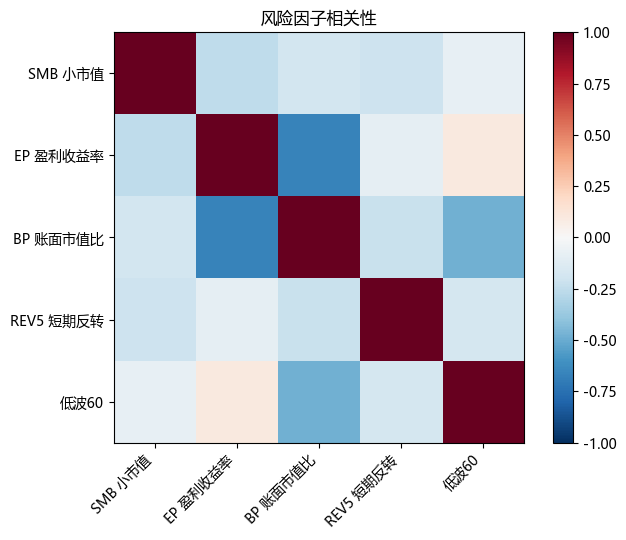

In [2]:
corr_f = model['Sigma_f'].corr()
plt.figure(figsize=(7, 5.5))
plt.imshow(corr_f, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr_f)), corr_f.columns, rotation=45, ha='right')
plt.yticks(range(len(corr_f)), corr_f.columns)
plt.title('风险因子相关性'); plt.tight_layout(); plt.show()

## 六、风险归因：组合的风险来自哪里

In [3]:
# 构造一个 Top30 小市值组合（有明显风格偏向），分解其风险
dt = ret.index[-1]
B_t = pd.DataFrame({k: exposures[k].loc[dt] for k in exp_names}).fillna(0)
top = facs['SMB 小市值'].loc[dt].dropna().nlargest(30).index
w = pd.Series(0.0, index=B_t.index)
w[B_t.index.intersection(top)] = 1.0/len(top)
w = w.values
# 组合层面因子暴露
port_factor_exp = B_t.values.T @ w
Sf = model['Sigma_f'].values
factor_var = port_factor_exp @ Sf @ port_factor_exp
specific_var = (w**2 * model['specific_risk'].reindex(B_t.index).fillna(0).values).sum()
print('组合年化方差分解:')
print('  因子风险: %.4f' % factor_var)
print('  特质风险: %.4f' % specific_var)
print('  各因子风险贡献:')
contr = port_factor_exp * (Sf @ port_factor_exp)
for k, c in zip(exp_names, contr):
    print('    %-12s %+.4f' % (k, c))

组合年化方差分解:
  因子风险: 0.0073
  特质风险: 0.0048
  各因子风险贡献:
    SMB 小市值      +0.0040
    EP 盈利收益率     +0.0015
    BP 账面市值比     -0.0000
    REV5 短期反转    +0.0015
    低波60         +0.0003


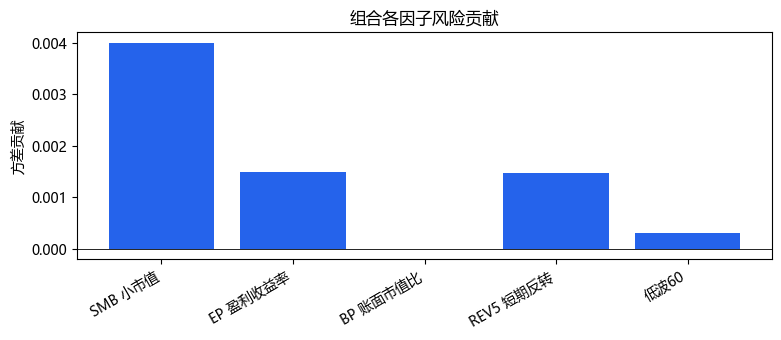

In [4]:
# 风险归因柱状图
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(len(exp_names)), contr, color='#2563eb')
ax.axhline(0, color='black', lw=.6)
ax.set_xticks(range(len(exp_names))); ax.set_xticklabels(exp_names, rotation=30, ha='right')
ax.set_title('组合各因子风险贡献'); ax.set_ylabel('方差贡献')
plt.tight_layout(); plt.show()

## 七、协方差收缩（Ledoit-Wolf）

除了因子模型，**协方差收缩**是另一种稳健估计：把样本协方差向一个结构化目标（如对角矩阵）加权混合：
$$\Sigma_{\text{shrink}} = (1-\delta)\Sigma_{\text{sample}} + \delta F_{\text{target}}$$
- sklearn 的 `sklearn.covariance.LedoitWolf` 可直接计算最优收缩强度 $\delta$；
- 保证正定、降低估计误差。

> 实践中：因子模型（Barra）+ 收缩 + 约束，共同保证协方差稳定。

## 八、小结与面试要点

- 收益/风险分解为因子（系统性）+ 特质（可分散）；因子风险模型 $\Sigma = B\Sigma_f B^\top + D$。
- 因子模型大幅减少待估参数，稳定、可解释；Barra 风格因子用于控风险。
- 风险归因把组合风险分解到各因子；协方差收缩（Ledoit-Wolf）进一步稳健化。

**面试高频：**
- Barra 风险模型的结构？（答：暴露 B、因子协方差 Σ_f、特质 D，Σ=BΣ_fB^T+D）
- 风险因子和 alpha 因子的区别？（答：风险因子解释/控制风险，alpha 因子提供超额）
- 为什么不用样本协方差？（答：参数多、噪声大、可能非正定，优化器放大误差）
- 怎么做组合风险归因？（答：组合因子暴露 × 因子协方差，分解各因子贡献）

## 动手练习
1. 用 LedoitWolf 估计协方差，对比样本协方差；
2. 改变风险因子数量，观察风险归因变化；
3. 构造一个高市值倾斜组合，看 Size 因子的风险贡献。

---
下一节 **5.4 优化器与约束：行业/风格/换手/风险约束下的组合优化**。